In [274]:
import numpy as np
import matplotlib.pyplot as plt
from mpmath import mp, jtheta
from tqdm import tqdm
import random
import math

In [275]:
def Jacobi_theta_1(z, omega):
    """Jacobi theta with early convergence stopping."""
    out = np.zeros_like(z, dtype=complex)
    n_max = 150
    
    for n in range(-n_max, n_max + 1):
        exp1 = 1j * np.pi * (n + 0.5)**2 * omega
        exp2 = 2 * np.pi * 1j * (n + 0.5) * (z - 0.5)
        
        # Skip terms with huge exponents
        if np.max(np.abs(np.real(exp1))) > 50 or np.max(np.abs(np.real(exp2))) > 50:
            continue
        
        with np.errstate(over='ignore', invalid='ignore'):  # Suppress warnings temporarily
            term = np.exp(exp1) * np.exp(exp2)
            term = np.nan_to_num(term, nan=0, posinf=0, neginf=0)  # Replace NaN/inf with 0
            out += term
    
    return out

In [276]:
def Jacobi_theta_1_direct(z, omega):
    return jtheta(1, np.pi * z, np.exp(1j * np.pi * omega))

In [277]:
# Lattice parameters
a1 = 1 + 0j  # Lattice vector 1
a2 = 1j  # Lattice vector 2
area = np.abs(np.imag(a1 * np.conj(a2)))  # Area of the unit cell
omega = a2 / a1  # Complex structure of the lattice
g1 = 2 * np.pi * 1j * a1 / area  # Reciprocal lattice vector 1
g2 = 2 * np.pi * -1j * a2 / area  # Reciprocal lattice vector 2 

In [278]:
def phi(z, k):

    theta = Jacobi_theta_1(z/a1 - k/g2, omega) 
    z_term = np.exp(np.pi * ((z/a1)**2 - (abs(z/a1))**2) / (2*np.imag(omega)))
    k_term = np.exp(np.pi * ((k/g2)**2 - (abs(k/g2))**2) / (2*np.imag(omega)))
    phase_term = np.exp(1j * (np.real(k)*np.real(a1) +np.imag(k)*np.imag(a1)) * z/a1)
    return theta * z_term * k_term * phase_term

In [279]:
def normalize_phi(z, k):
    """Normalize the wavefunction phi."""
    norm_factor = np.sqrt(np.sum(np.abs(phi(z, k))**2))
    return phi(z, k) / norm_factor

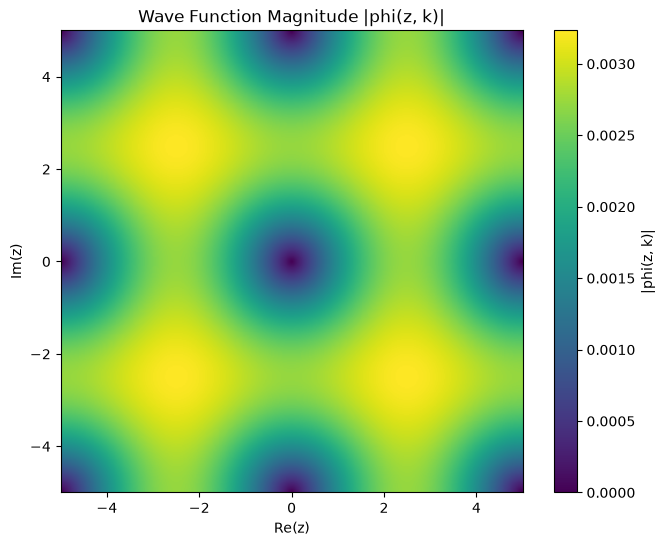

In [381]:
x = np.linspace(-1, 1, 400)
y = np.linspace(-1, 1, 400)
X, Y = np.meshgrid(x, y)
Z = X + 1j * Y

k = 0 + 0j  # Example momentum
F = np.abs(normalize_phi(Z, k))  # Evaluate the normalized wave function on the grid
plt.figure(figsize=(8, 6))
plt.imshow(F, extent=(-5, 5, -5, 5), origin='lower', cmap='viridis')
plt.colorbar(label='|phi(z, k)|')
plt.title('Wave Function Magnitude |phi(z, k)|')
plt.xlabel('Re(z)')
plt.ylabel('Im(z)')
plt.show()

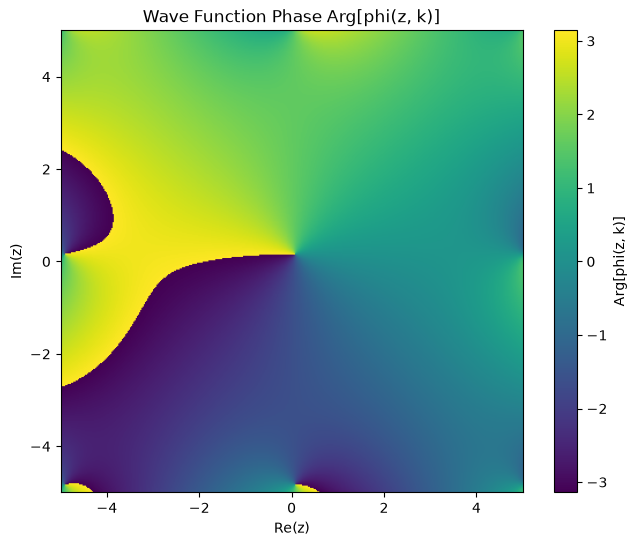

In [391]:
x = np.linspace(-1, 1, 400)
y = np.linspace(-1, 1, 400)
X, Y = np.meshgrid(x, y)
Z = X + 1j * Y

k = 0.1 + 0.2j  # Example momentum
F = np.angle(normalize_phi(Z, k))  # Evaluate the wave function on the grid
plt.figure(figsize=(8, 6))
plt.imshow(F, extent=(-5, 5, -5, 5), origin='lower', cmap='viridis')
plt.colorbar(label='Arg[phi(z, k)]')
plt.title('Wave Function Phase Arg[phi(z, k)]')
plt.xlabel('Re(z)')
plt.ylabel('Im(z)')
plt.show()


In [402]:
def overlap_integral(k1, k2):
    """Compute the overlap integral between two wavefunctions."""
    # Define a grid for numerical integration
    x = np.linspace(-5, 5, 1000)
    y = np.linspace(-5, 5, 1000)
    X, Y = np.meshgrid(x, y)
    Z = X + 1j * Y
    
    # Compute the wavefunctions
    phi1 = phi(Z, k1)
    phi2 = phi(Z, k2)
    
    # Compute the overlap integral
    integrand = np.conj(phi1) * phi2
    overlap_unnormalised = np.trapezoid(np.trapezoid(integrand.real, x), y) + 1j * np.trapezoid(np.trapezoid(integrand.imag, x), y)
    overlap = overlap_unnormalised / (np.sqrt(np.trapezoid(np.trapezoid(np.abs(phi1)**2, x), y)) * np.sqrt(np.trapezoid(np.trapezoid(np.abs(phi2)**2, x), y)))
    return overlap

In [400]:
def overlap_integral_montecarlo(k1, k2):
    """Compute the overlap integral using Monte Carlo integration."""

    a = -5
    b = 5
    dx = 2*(10)**(-3)

    num_samples=1000

    n = random.randint(0, int((b-a)/dx))
    m = random.randint(0, int((b-a)/dx))
    random_x = a + n*dx
    random_y = a + m*dx

    z_initial = random_x + 1j * random_y
    
    # Compute the wavefunctions at the sampled points
    phi1 = normalize_phi(z_initial, k1)
    phi2 = normalize_phi(z_initial, k2)

    integral = 0
    norm1 = 0
    norm2 = 0
    i = 0

    while i < num_samples:
        integral += np.conj(phi1) * phi2
        
        n = random.randint(0, int((b-a)/dx))
        m = random.randint(0, int((b-a)/dx))
        random_x = a + n*dx
        random_y = a + m*dx
        
        z_new = random_x + 1j * random_y

        p1 = min(1, (np.abs(normalize_phi(z_new, k1) / phi1))**2)
        p2 = min(1, (np.abs(normalize_phi(z_new, k2) / phi2))**2)

        if random.uniform(0, 1) < p1 or random.uniform(0, 1) < p2:
            phi1 = normalize_phi(z_new, k1)
            phi2 = normalize_phi(z_new, k2)

        i += 1
    
    return integral / num_samples

In [403]:
print(overlap_integral(1, 1 + 1j*0.001))
print(overlap_integral_montecarlo(1, 1 + 1j*0.001))

(0.9999999091195176+7.95774644818852e-05j)
(0.9999999385029732+7.906005285702974e-05j)


In [404]:
n = 5
p = 6
omc = []
k = 1
while k < p+1:
    i = 1
    t = 10**(-k)
    while i < n+1:
        omc.append(overlap_integral_montecarlo(0, (1+1j)*t))
        i += 1
    print(np.var(omc)/ t**2)
    k +=1



0.010003827740034945


KeyboardInterrupt: 

In [ ]:
n=5
omc = []
t = 0.1
while i < n+1:
    omc.append(overlap_integral_montecarlo(0, (1+1j)*t))
    i += 1
o = overlap_integral(0, t)
omc_av = np.average(omc)
error = (o - omc_av)

print(error)


KeyboardInterrupt: 

100%|██████████| 4/4 [44:10:36<00:00, 39759.13s/it]     


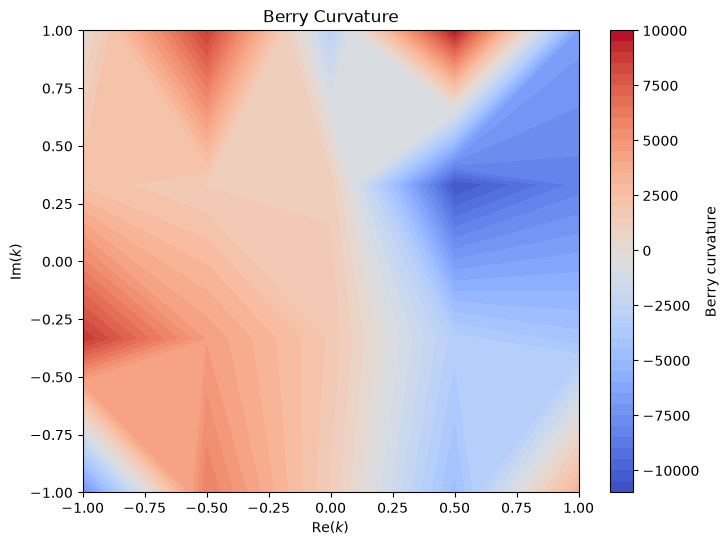

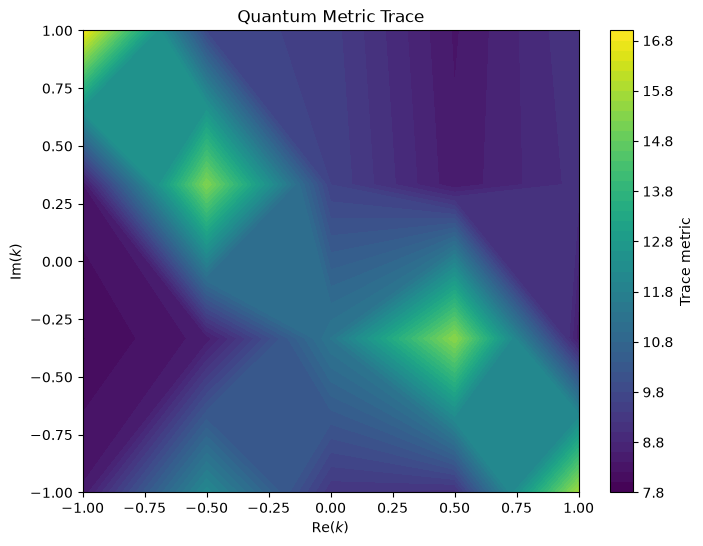

In [390]:
k = np.meshgrid(np.linspace(-1, 1, 5), np.linspace(-1, 1, 4))
dk = 0.0001
berry_curvatures = []
trace_metrics = []
for i in tqdm(range(k[0].shape[0])):
    for j in range(k[0].shape[1]):
        k_point = k[0][i, j] + 1j * k[1][i, j]
        k_point_x = k_point + dk
        k_point_y = k_point + 1j * dk
        k_point_xy = k_point + dk + 1j * dk

        overlap_1 = overlap_integral_montecarlo(k_point, k_point_x)
        overlap_2 = overlap_integral_montecarlo(k_point_x, k_point_xy)
        overlap_3 = overlap_integral_montecarlo(k_point_xy, k_point_y)
        overlap_4 = overlap_integral_montecarlo(k_point_y, k_point)

        g_xx = (1 - np.abs(overlap_1)**2)/ dk**2
        g_yy = (1 - np.abs(overlap_4)**2)/ dk**2

        trace_metric = g_xx + g_yy
        trace_metrics.append(trace_metric)
        berry_curvature = (
            -np.angle(overlap_1 * overlap_2 * overlap_3 * overlap_4)
            / dk**2
        )
        berry_curvatures.append(berry_curvature)

berry_curvature_grid = np.asarray(berry_curvatures).reshape(k[0].shape)

plt.figure(figsize=(8, 6))
plt.contourf(k[0], k[1], berry_curvature_grid, levels=50, cmap="coolwarm")
plt.colorbar(label="Berry curvature")
plt.xlabel(r"$\mathrm{Re}(k)$")
plt.ylabel(r"$\mathrm{Im}(k)$")
plt.title("Berry Curvature")
plt.show()

trace_metric_grid = np.asarray(trace_metrics).reshape(k[0].shape)

plt.figure(figsize=(8, 6))
plt.contourf(k[0], k[1], trace_metric_grid, levels=50, cmap="viridis")
plt.colorbar(label="Trace metric")
plt.xlabel(r"$\mathrm{Re}(k)$")
plt.ylabel(r"$\mathrm{Im}(k)$")
plt.title("Quantum Metric Trace")
plt.show()
